## Imports ##

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Reproductibilité
np.random.seed(42)


## Chargement dataset ##

In [2]:
df = pd.read_csv('../../Données/X_train_clean.csv')
print(f"Dimensions : {df.shape}")
df.head()

Dimensions : (444, 34)


,Family_Size,PPI_Intersection,PPI_Union,PPI_Jaccard,Pfam_Inter,Pfam_Union,Pfam_Jaccard,Ks,Ka,Ka_Ks,...,Expression_Data_Missing,TE_Env_Pair_TE-free_TE-free,TE_Env_Pair_TE-free_TE-poor,TE_Env_Pair_TE-free_TE-rich,TE_Env_Pair_TE-poor_TE-poor,TE_Env_Pair_TE-poor_TE-rich,TE_Env_Pair_TE-rich_TE-rich,TE_Env_Class_free,TE_Env_Class_half,TE_Env_Class_rich
0,4,1.0,9.0,11.111111,1.0,1.0,1.0,1.8192,0.4049,0.222570,...,0,True,False,False,False,False,False,True,False,False
1,4,1.0,14.0,7.142857,1.0,1.0,1.0,1.9732,0.4109,0.208240,...,0,False,False,True,False,False,False,False,True,False
2,2,12.0,32.0,37.500000,1.0,1.0,1.0,2.3106,0.5092,0.220376,...,0,True,False,False,False,False,False,True,False,False
3,17,1.0,14.0,7.142857,3.0,3.0,1.0,1.6167,0.3528,0.218222,...,0,False,True,False,False,False,False,False,True,False
4,17,0.0,7.0,0.000000,3.0,3.0,1.0,8.2558,0.4092,0.049565,...,0,False,True,False,False,False,False,False,True,False


In [3]:
print("=== Types de colonnes ===")
print(df.dtypes)

=== Types de colonnes ===
Family_Size                      int64
PPI_Intersection               float64
PPI_Union                      float64
PPI_Jaccard                    float64
Pfam_Inter                     float64
Pfam_Union                     float64
Pfam_Jaccard                   float64
Ks                             float64
Ka                             float64
Ka_Ks                          float64
Ks_SD                          float64
Ka_SD                          float64
Distance                       float64
TE_Coverage_Asymmetry          float64
TE_Coverage_Mean               float64
TE_Number_Asymmetry            float64
TE_Number_Mean                 float64
PPI_Interactant_Asymmetry      float64
PPI_Interactant_Mean           float64
Pfam_Asymmetry                 float64
Pfam_Mean                      float64
TE_Density_Asymmetry           float64
TE_Density_Mean                float64
TE_Env_Match                     int64
Expression_Data_Missing          int64

In [4]:
df['TE_Env_Match'].value_counts()

TE_Env_Match
1    289
0    155
Name: count, dtype: int64

In [5]:
df_classif = pd.read_csv('../../Données/Y_train_clean.csv')
df_classif['Classification'].value_counts()

Classification
1    262
0    182
Name: count, dtype: int64

In [6]:
# Récupérer les variables numériques et les stocker dans une liste
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
X_num = df[num_cols]

numeric_cols = X_num.columns.tolist()
print(f"Colonnes numériques : {numeric_cols}")

Colonnes numériques : ['Family_Size', 'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Ks', 'Ka', 'Ka_Ks', 'Ks_SD', 'Ka_SD', 'Distance', 'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean', 'Pfam_Asymmetry', 'Pfam_Mean', 'TE_Density_Asymmetry', 'TE_Density_Mean', 'TE_Env_Match', 'Expression_Data_Missing']


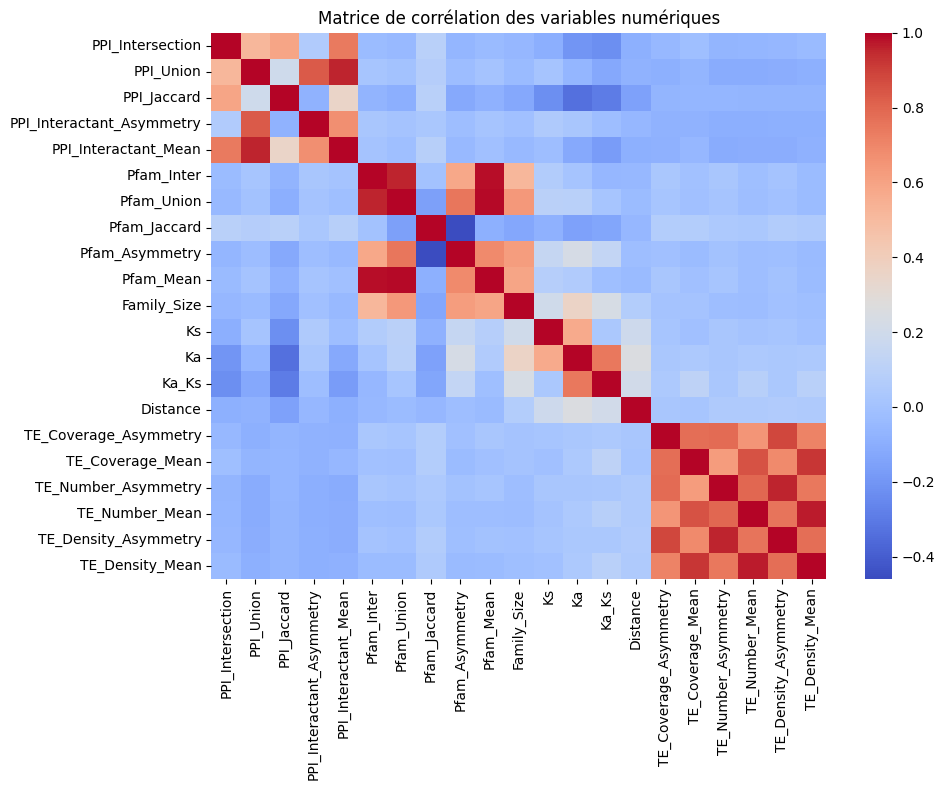

In [7]:
numeric_cols = [
    'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard', 'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean',
    'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard', 'Pfam_Asymmetry', 'Pfam_Mean', 'Family_Size',
    'Ks', 'Ka', 'Ka_Ks', 'Distance',
    'TE_Coverage_Asymmetry', 'TE_Coverage_Mean', 'TE_Number_Asymmetry', 'TE_Number_Mean',
    'TE_Density_Asymmetry', 'TE_Density_Mean',
]
# # Ordonner les colonnes numériques par mêmes préfixes, pour faciliter la lecture de la matrice de corrélation
# numeric_cols = sorted(numeric_cols, key=lambda x: (x.split('_')[0], x.split('_')[1] if len(x.split('_')) > 1 else ''))
# print(f"Colonnes numériques ordonnées : {numeric_cols}")

# Matrice de corrélation pour les variables numériques et visualisation avec une heatmap
plt.figure(figsize=(10, 8))
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt='.2f')
plt.title('Matrice de corrélation des variables numériques')
plt.tight_layout()
plt.savefig('../Plots/t_SNE_global/correlation_matrix.png', dpi=300)
plt.show()

/tmp/ipykernel_13911/1755129583.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


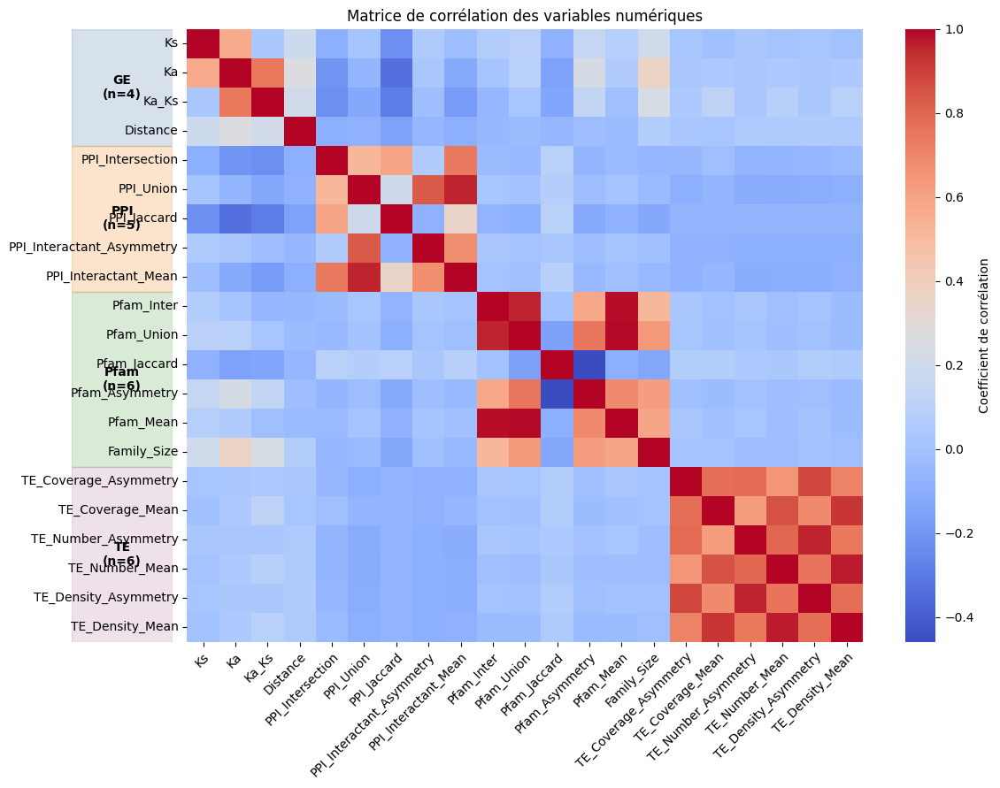

In [8]:
family_cols = {
    'GE': ['Ks', 'Ka', 'Ka_Ks', 'Distance'],
    'PPI': [
        'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard',
        'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean',
    ],
    'Pfam': [
        'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard',
        'Pfam_Asymmetry', 'Pfam_Mean', 'Family_Size',
    ],
    'TE': [
        'TE_Coverage_Asymmetry', 'TE_Coverage_Mean',
        'TE_Number_Asymmetry', 'TE_Number_Mean',
        'TE_Density_Asymmetry', 'TE_Density_Mean',
    ],
}
numeric_cols = [column for columns in family_cols.values() for column in columns]

corr_matrix = df[numeric_cols].corr()

fig = plt.figure(figsize=(14, 9))
grid = fig.add_gridspec(1, 2, width_ratios=(1.2, 10), wspace=0.03)
family_ax = fig.add_subplot(grid[0, 0])
heatmap_ax = fig.add_subplot(grid[0, 1])

sns.heatmap(
    corr_matrix,
    annot=False,
    cmap='coolwarm',
    fmt='.2f',
    ax=heatmap_ax,
    cbar_kws={'label': 'Coefficient de corrélation'},
)
heatmap_ax.set_title('Matrice de corrélation des variables numériques')
heatmap_ax.tick_params(axis='x', labelrotation=45)
plt.setp(heatmap_ax.get_xticklabels(), ha='right', rotation_mode='anchor')
heatmap_ax.tick_params(axis='y', labelrotation=0)

family_colors = {
    'GE': '#4C78A8',
    'PPI': '#F58518',
    'Pfam': '#54A24B',
    'TE': '#B279A2',
}
start = 0
for family, columns in family_cols.items():
    end = start + len(columns)
    family_ax.axhspan(start, end, color=family_colors[family], alpha=0.22)
    family_ax.text(
        0.5,
        (start + end) / 2,
        f'{family}\n(n={len(columns)})',
        ha='center',
        va='center',
        fontsize=10,
        fontweight='bold',
    )
    start = end

family_ax.set_xlim(0, 1)
family_ax.set_ylim(len(numeric_cols), 0)
family_ax.axis('off')

fig.tight_layout()
fig.savefig('../Plots/t_SNE_global/correlation_matrix_families.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_13911/3391037467.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


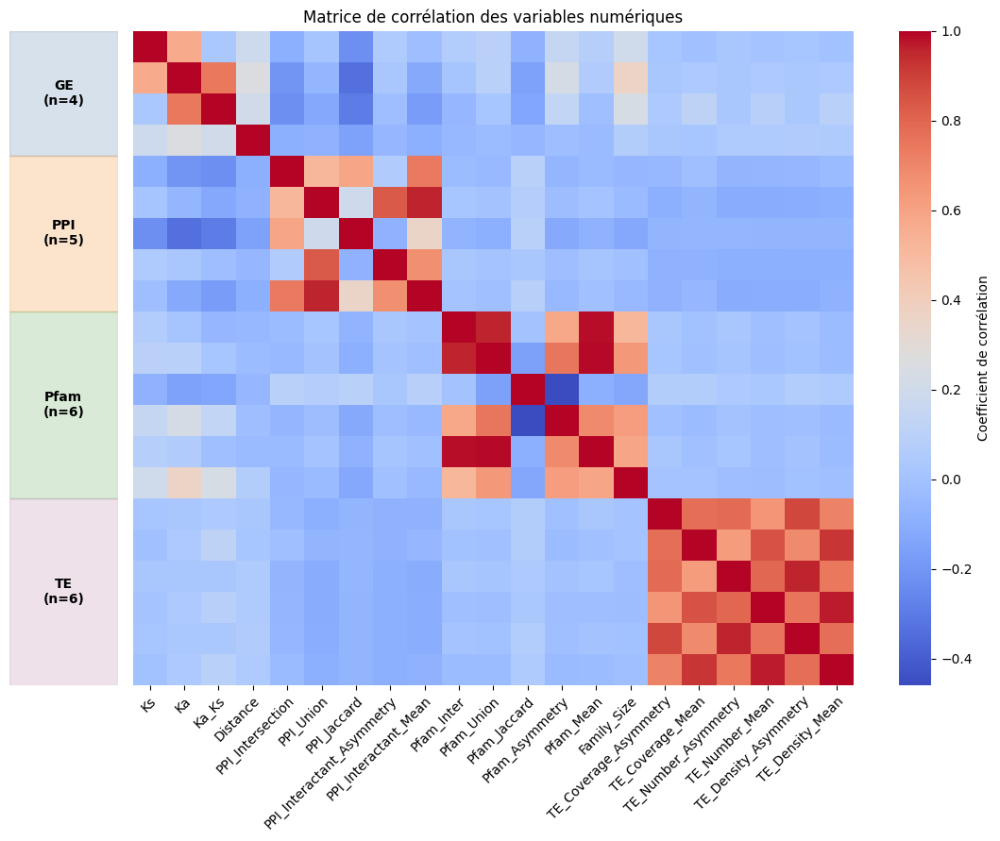

In [9]:
family_cols = {
    'GE': ['Ks', 'Ka', 'Ka_Ks', 'Distance'],
    'PPI': [
        'PPI_Intersection', 'PPI_Union', 'PPI_Jaccard',
        'PPI_Interactant_Asymmetry', 'PPI_Interactant_Mean',
    ],
    'Pfam': [
        'Pfam_Inter', 'Pfam_Union', 'Pfam_Jaccard',
        'Pfam_Asymmetry', 'Pfam_Mean', 'Family_Size',
    ],
    'TE': [
        'TE_Coverage_Asymmetry', 'TE_Coverage_Mean',
        'TE_Number_Asymmetry', 'TE_Number_Mean',
        'TE_Density_Asymmetry', 'TE_Density_Mean',
    ],
}
numeric_cols = [column for columns in family_cols.values() for column in columns]

corr_matrix = df[numeric_cols].corr()

fig = plt.figure(figsize=(14, 9))
grid = fig.add_gridspec(1, 2, width_ratios=(1.2, 10), wspace=0.03)
family_ax = fig.add_subplot(grid[0, 0])
heatmap_ax = fig.add_subplot(grid[0, 1])

sns.heatmap(
    corr_matrix,
    annot=False,
    cmap='coolwarm',
    fmt='.2f',
    ax=heatmap_ax,
    cbar_kws={'label': 'Coefficient de corrélation'},
)
heatmap_ax.set_title('Matrice de corrélation des variables numériques')
heatmap_ax.tick_params(axis='x', labelrotation=45)
plt.setp(heatmap_ax.get_xticklabels(), ha='right', rotation_mode='anchor')
heatmap_ax.tick_params(axis='y', left=False, labelleft=False)

family_colors = {
    'GE': '#4C78A8',
    'PPI': '#F58518',
    'Pfam': '#54A24B',
    'TE': '#B279A2',
}

start = 0
for family, columns in family_cols.items():
    end = start + len(columns)
    family_ax.axhspan(start, end, color=family_colors[family], alpha=0.22)
    family_ax.text(
        0.5,
        (start + end) / 2,
        f'{family}\n(n={len(columns)})',
        ha='center',
        va='center',
        fontsize=10,
        fontweight='bold',
    )
    start = end

family_ax.set_xlim(0, 1)
family_ax.set_ylim(len(numeric_cols), 0)
family_ax.axis('off')

fig.tight_layout()
fig.savefig(
    '../Plots/t_SNE_global/correlation_matrix_families.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

In [15]:
print("\n=== Valeurs manquantes ===")
missing = df.isnull().sum()
print(missing[missing > 0])


=== Valeurs manquantes ===
Series([], dtype: int64)


In [16]:
df.describe()

,Family_Size,PPI_Intersection,PPI_Union,PPI_Jaccard,Pfam_Inter,Pfam_Union,Pfam_Jaccard,Ks,Ka,Ka_Ks,...,TE_Number_Asymmetry,TE_Number_Mean,PPI_Interactant_Asymmetry,PPI_Interactant_Mean,Pfam_Asymmetry,Pfam_Mean,TE_Density_Asymmetry,TE_Density_Mean,TE_Env_Match,Expression_Data_Missing
count,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,...,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000,444.000000
mean,10.252252,4.664414,19.036036,15.831285,2.430180,2.815315,0.904575,1.610206,0.314486,0.193110,...,1.472973,1.015766,9.227477,11.850225,0.308559,2.622748,0.200702,0.139652,0.650901,0.141892
std,25.587885,14.294942,33.319624,25.377433,2.512648,3.372594,0.219169,0.928977,0.250372,0.118174,...,1.743531,1.164166,24.775563,21.260068,0.874427,2.912594,0.235102,0.158360,0.477223,0.349333
min,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.060400,-0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,2.000000,0.000000,1.000000,1.000000,1.000000,0.843675,0.108300,0.102773,...,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
50%,4.000000,0.000000,8.000000,0.000000,2.000000,2.000000,1.000000,1.580400,0.240350,0.169878,...,1.000000,0.500000,2.000000,4.500000,0.000000,2.000000,0.144782,0.087444,1.000000,0.000000
75%,10.000000,4.000000,21.000000,22.222222,3.000000,3.000000,1.000000,2.101425,0.442650,0.263050,...,2.000000,1.500000,8.000000,13.000000,0.000000,3.000000,0.309307,0.212718,1.000000,0.000000
max,192.000000,133.000000,308.000000,100.000000,17.000000,24.000000,1.000000,8.255800,1.041500,0.644444,...,12.000000,7.500000,293.000000,158.500000,9.000000,19.500000,1.366138,1.050148,1.000000,1.000000


## Preprocessing des variables ##

In [17]:
X = df[numeric_cols].copy()

# Imputation des NaN par la médiane
X = X.fillna(X.median(numeric_only=True))

# Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## t-SNE sans PCA ##

### t-SNE Classification sans PCA init = random ###

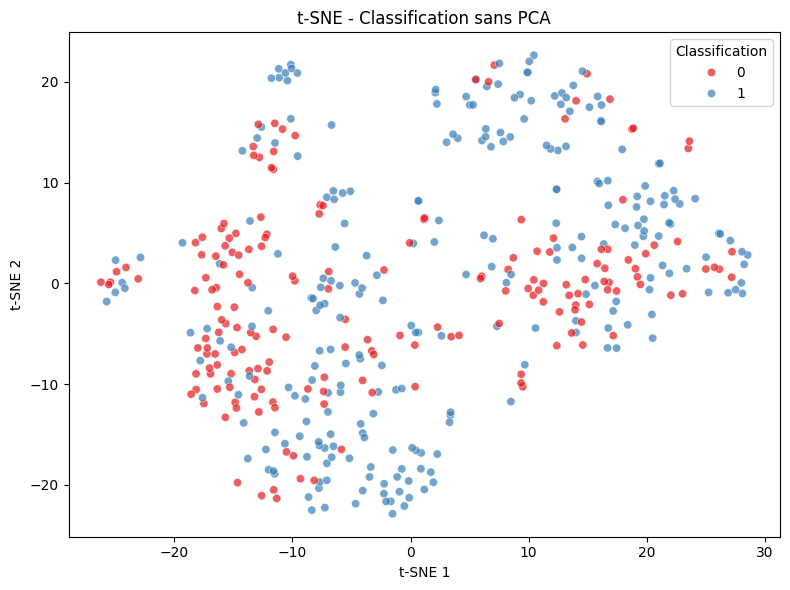

In [18]:
# t-SNE avec initialisation aléatoire et apprentissage automatique
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    max_iter=1000,
    init='random',
    random_state=42
)

# Récupérer Classification pour t-SNE 
y_train = pd.read_csv("../Données/Y_train_clean.csv")

X_tsne_random = tsne.fit_transform(X_scaled)

df_tsne_random = pd.DataFrame(X_tsne_random, columns=['tSNE_1', 'tSNE_2'])
df_tsne_random['orig_index'] = df.index

# Visualisation t-SNE colorée par la Classification
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df_tsne_random['tSNE_1'], y=df_tsne_random['tSNE_2'], hue=y_train['Classification'], palette='Set1', alpha=0.7)
plt.title('t-SNE - Classification sans PCA')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='Classification')
plt.tight_layout()
plt.savefig('Plots/t_SNE_global/sans_pca/tsne_classification.png', dpi=300)
plt.show()

### Analyse perplexité t-SNE Classification sans PCA ###

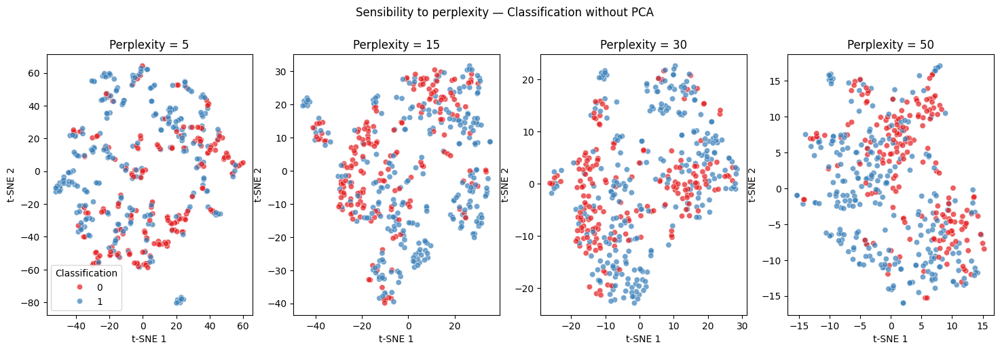

In [19]:
# Analyse de la sensibilité de t-SNE à la perplexité
perplexities = [5, 15, 30, 50]
fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 5))
group_col = 'Classification' if 'Classification' in y_train.columns else print("Colonne 'Classification' non trouvée.")
for i, perp in enumerate(perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        learning_rate='auto',
        max_iter=1000,
        init='random',
        random_state=42,
    )
    X_tsne_perp_random = tsne.fit_transform(X_scaled)
    df_tsne_perp_random = pd.DataFrame(X_tsne_perp_random, columns=['tSNE_1', 'tSNE_2'])
    df_tsne_perp_random['orig_index'] = df.index
    
    sns.scatterplot(x=df_tsne_perp_random['tSNE_1'], y=df_tsne_perp_random['tSNE_2'], hue=y_train['Classification'], palette='Set1', alpha=0.7, ax=axes[i])
    axes[i].set_title(f'Perplexity = {perp}')
    axes[i].set_xlabel('t-SNE 1')
    axes[i].set_ylabel('t-SNE 2')
    if i == 0:
        axes[i].legend(title='Classification')
    else:
        axes[i].get_legend().remove()
plt.suptitle(f"Sensibility to perplexity — {group_col} without PCA", y=1.02)
# Supprimer les axes vides s'il y en a
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.savefig(f'Plots/t_SNE_global/sans_pca/sensitivity_perplexity.png', dpi=150, bbox_inches='tight')
plt.show()

### Overlay des features numériques sans PCA ###

On superpose une variable continue sur la carte t-SNE pour voir comment elle se structure dans l'espace réduit.

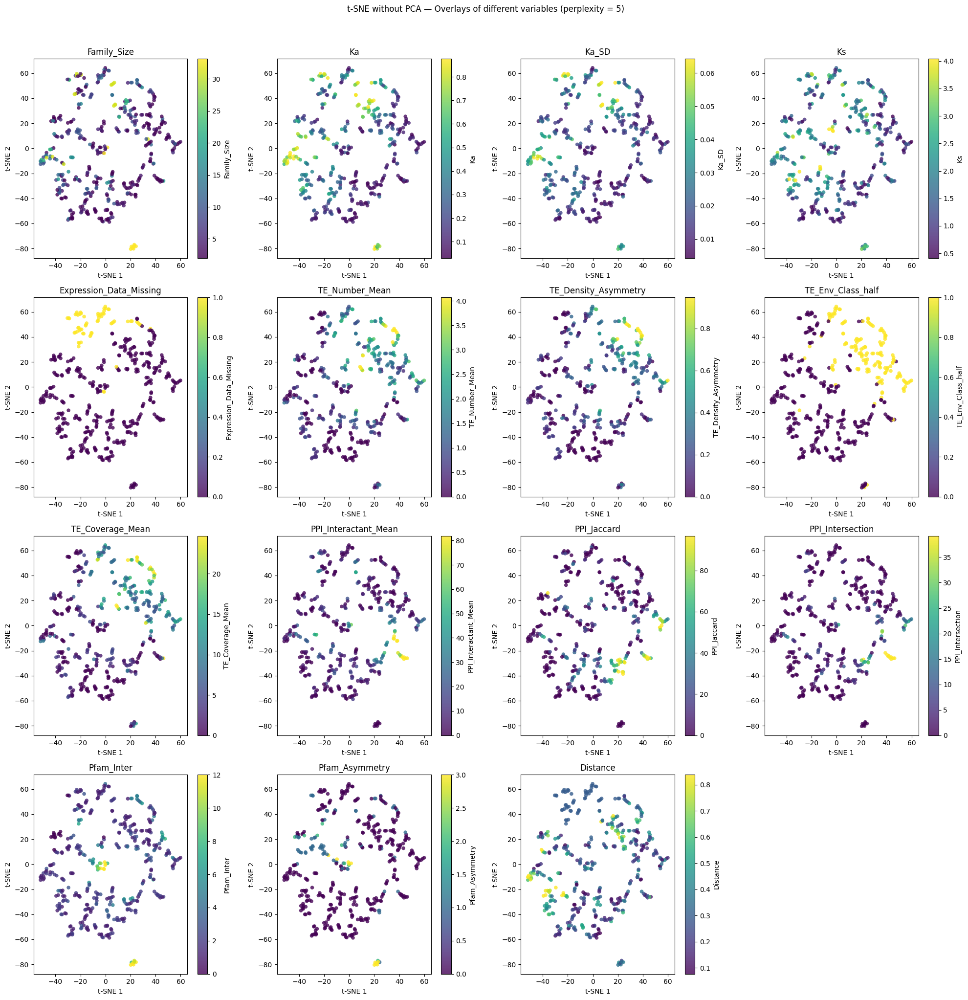

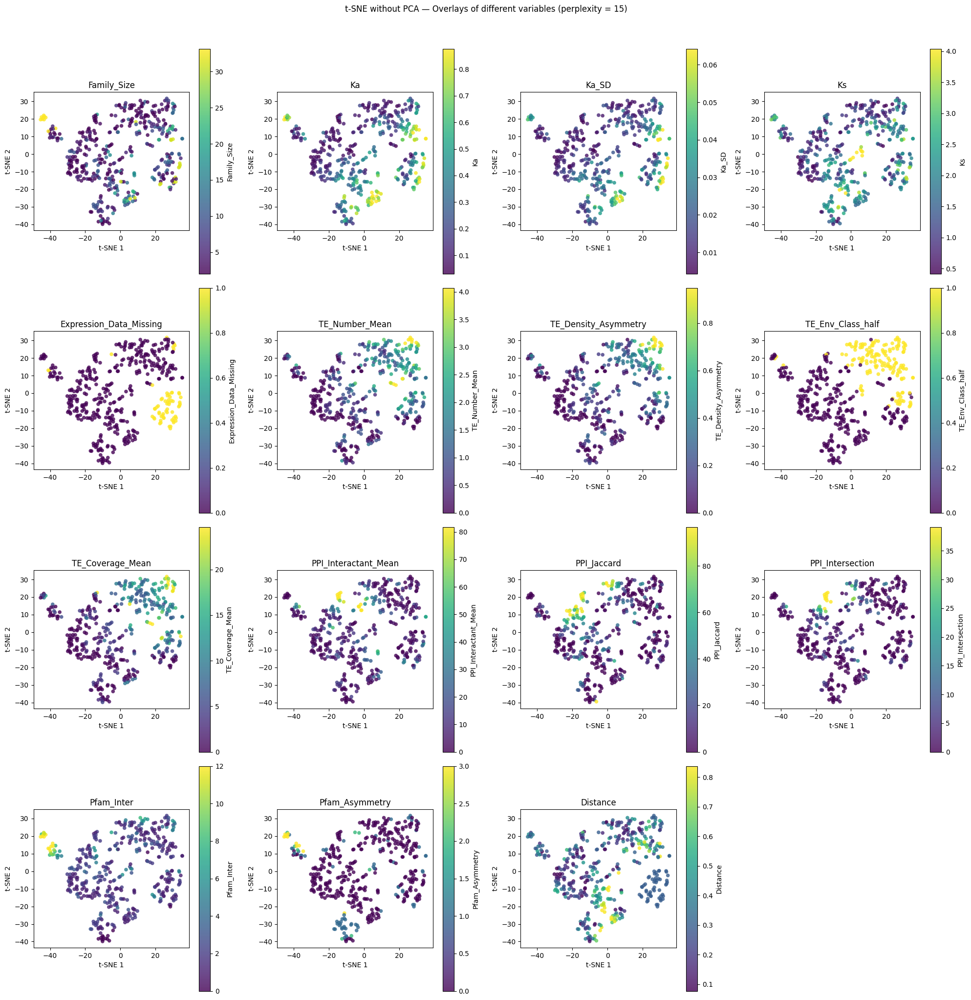

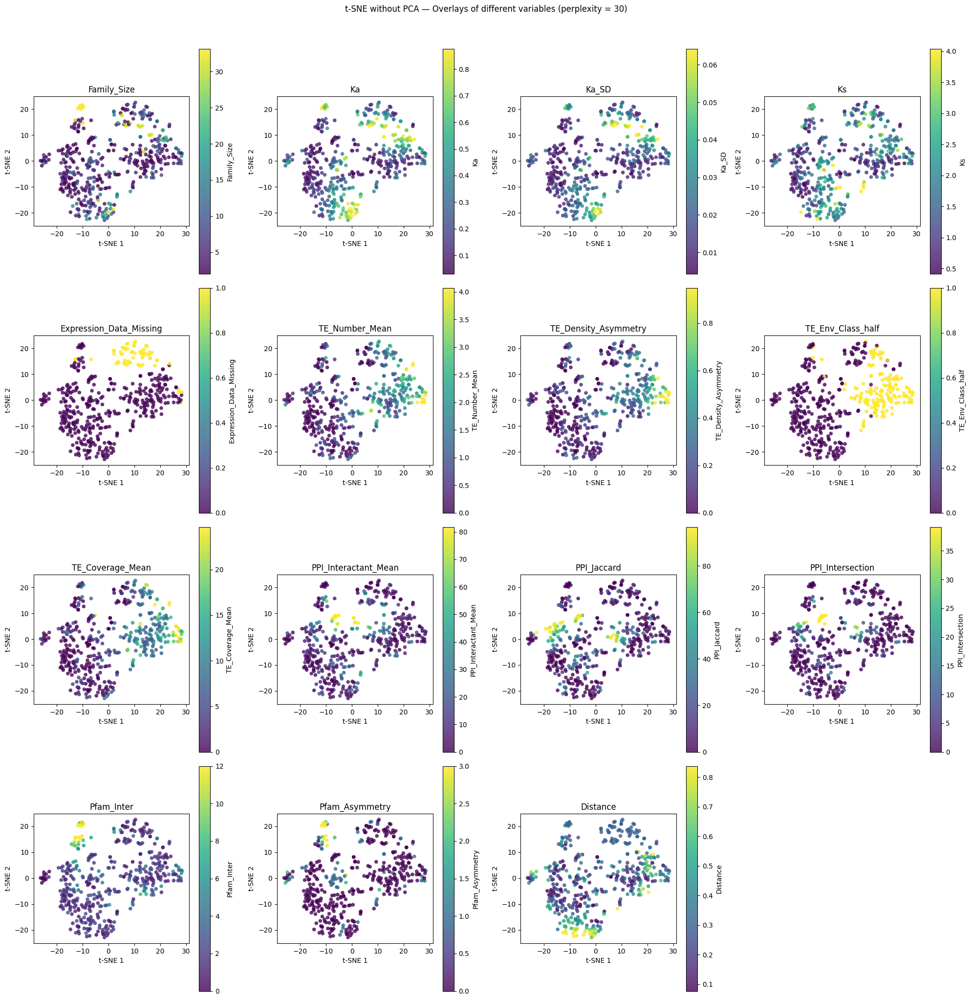

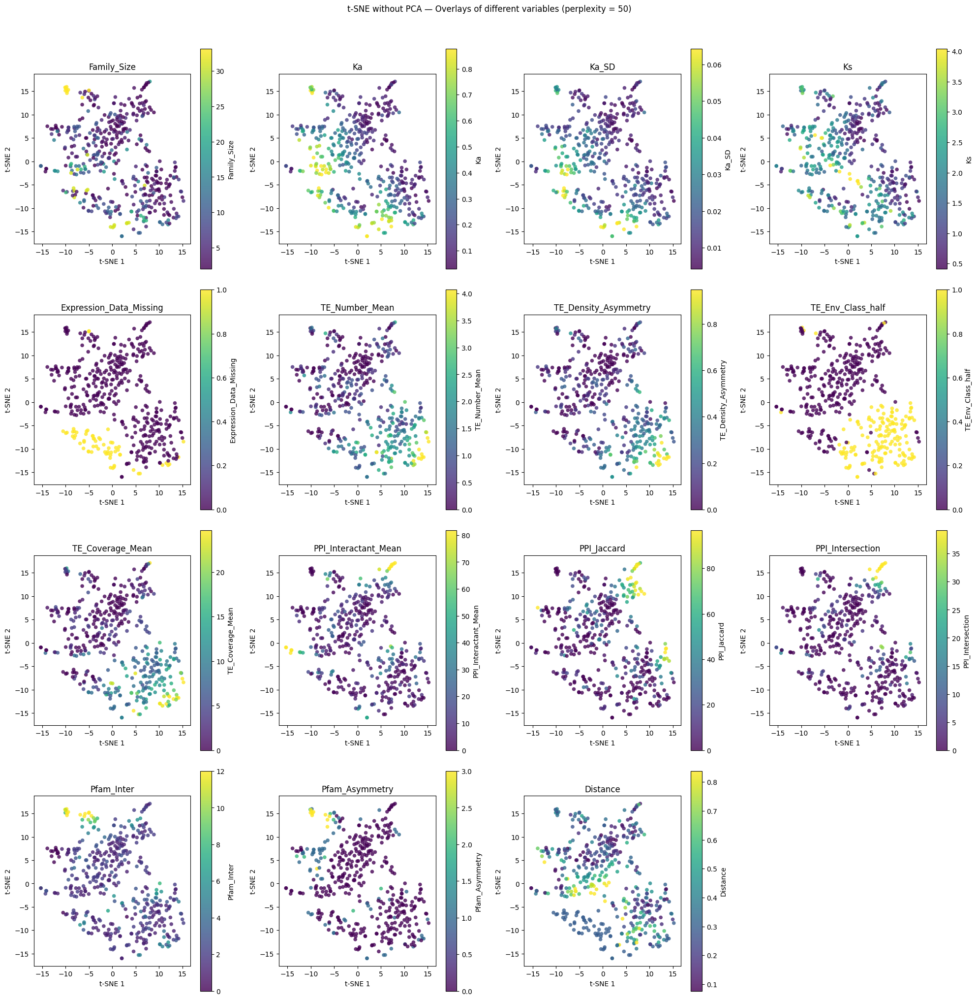

In [13]:
# Fenetre avec 14 overlay pour les variables d'intérêt récupérés via elactic net
features_to_overlay = [
    'Family_Size',
    'Ka', 'Ka_SD', 'Ks',
    'Expression_Data_Missing',
    'TE_Number_Mean', 'TE_Density_Asymmetry', 'TE_Env_Class_half', 'TE_Coverage_Mean',
    'PPI_Interactant_Mean', 'PPI_Jaccard', 'PPI_Intersection',
    'Pfam_Inter', 'Pfam_Asymmetry',
    'Distance'
]
# Figures par descripteurs pour différentes perplexités
perplexities = [5, 15, 30, 50]
for perp in perplexities:
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        learning_rate='auto',
        max_iter=1000,
        init='random',
        random_state=42
    )
    X_tsne_perp_random = tsne.fit_transform(X_scaled)
    df_tsne_perp_random = pd.DataFrame(X_tsne_perp_random, columns=['tSNE_1', 'tSNE_2'])
    df_tsne_perp_random['orig_index'] = df.index

    fig, axes = plt.subplots(4, 4, figsize=(20, 20))
    axes = axes.flatten()
    for i, feature in enumerate(features_to_overlay):
        if feature not in df.columns:
            axes[i].set_visible(False)
            continue

        vals = df[feature].values
        if vals.dtype == bool:
            vals = vals.astype(int)

        vmin, vmax = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)
        sc = axes[i].scatter(
            df_tsne_perp_random['tSNE_1'], df_tsne_perp_random['tSNE_2'],
            c=vals, cmap='viridis', vmin=vmin, vmax=vmax,
            alpha=0.8, s=30, edgecolors='none'
        )
        axes[i].set_title(feature)
        axes[i].set_xlabel('t-SNE 1')
        axes[i].set_ylabel('t-SNE 2')
        axes[i].set_aspect('equal')
        plt.colorbar(sc, ax=axes[i], label=feature)

    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f't-SNE without PCA — Overlays of different variables (perplexity = {perp})', y=1.02)
    plt.tight_layout()
    plt.savefig(f'Plots/t_SNE_global/sans_pca/overlay/perplexité_{perp}.png', dpi=150, bbox_inches='tight')
    plt.show()

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


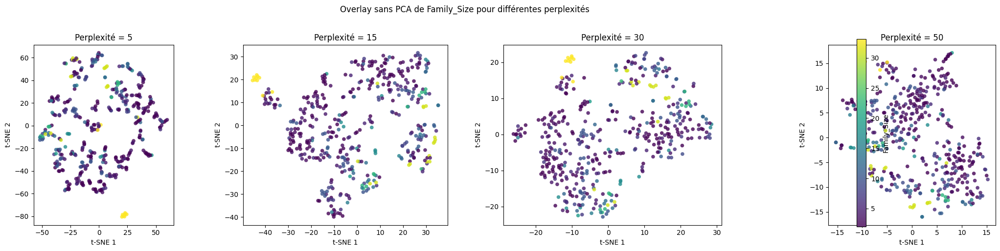

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


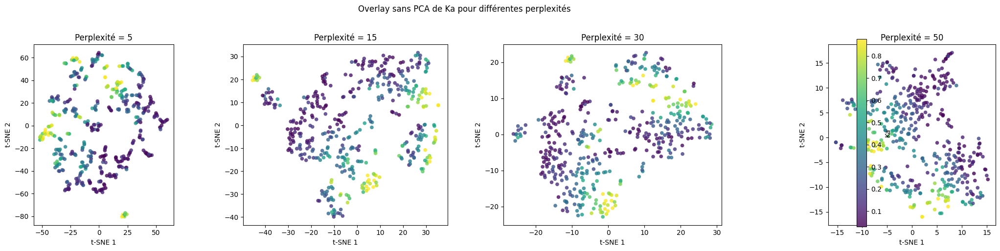

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


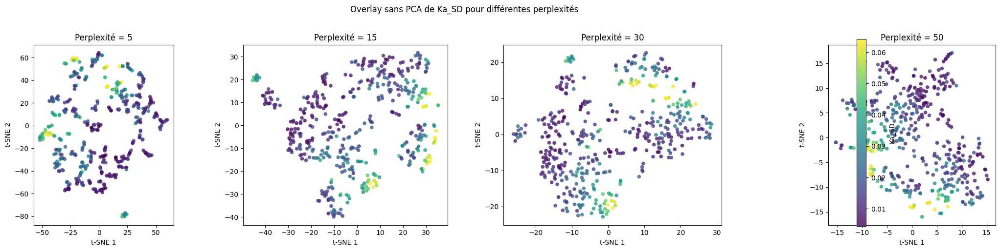

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


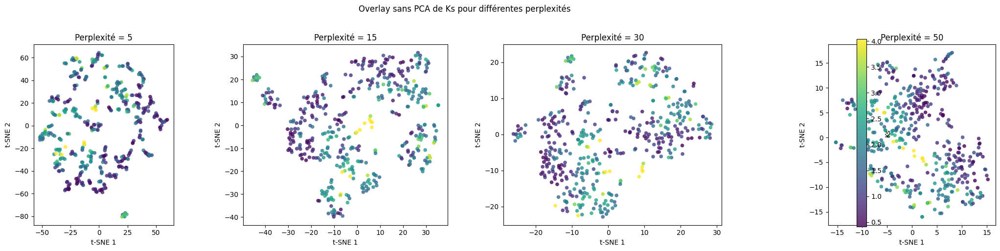

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


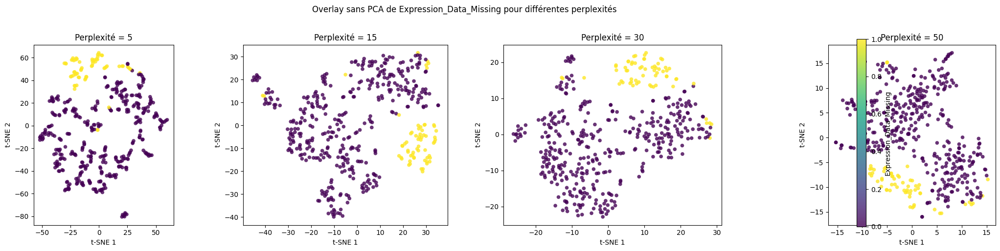

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


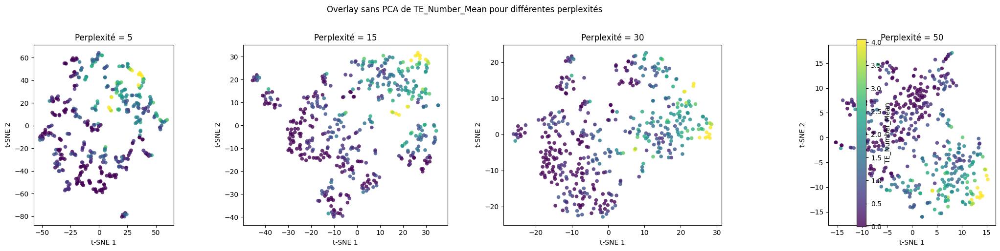

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


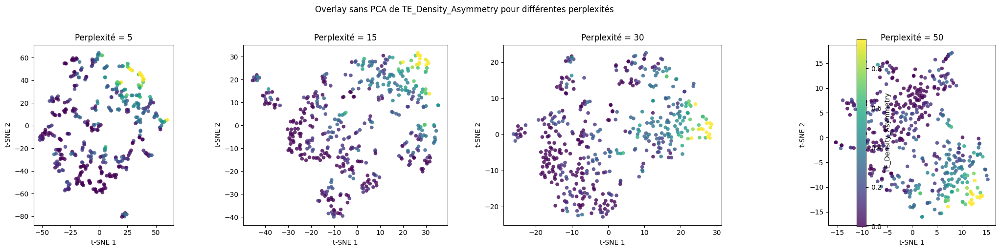

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


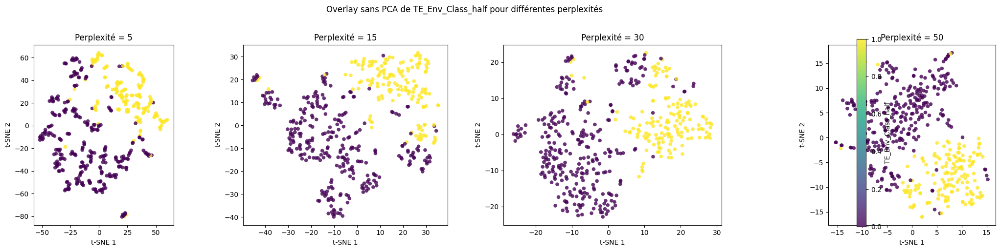

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


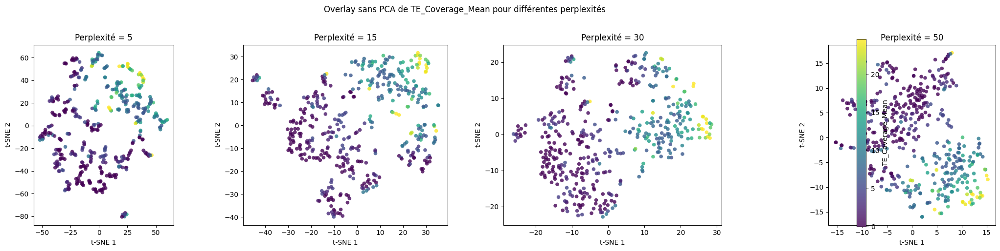

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


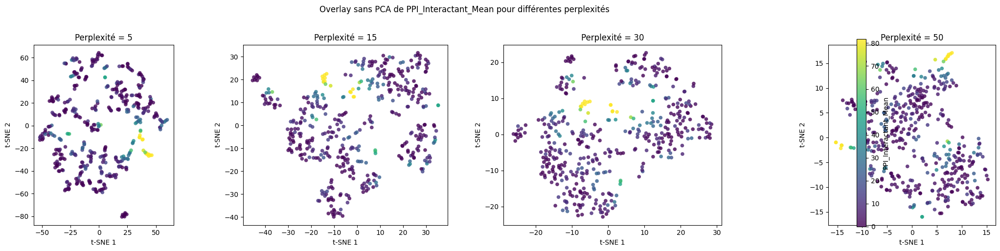

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


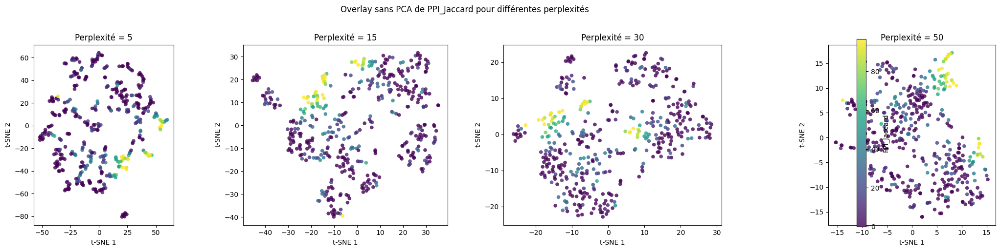

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


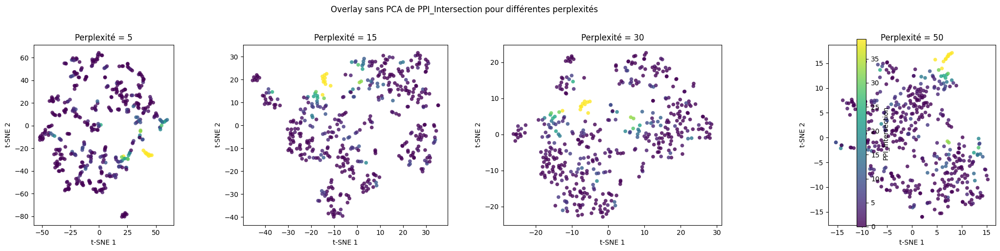

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


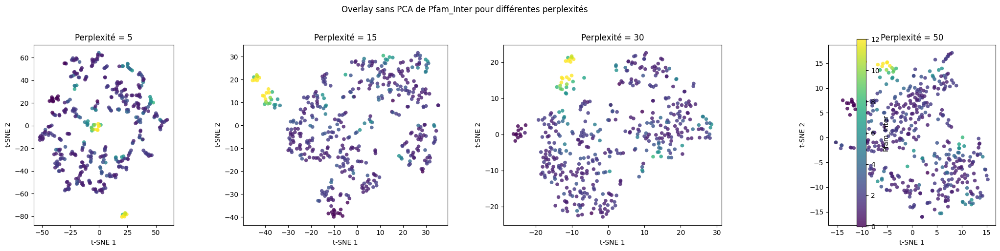

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


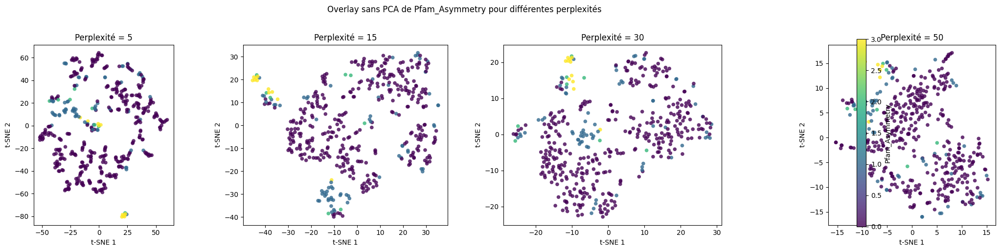

/tmp/ipykernel_9354/145114592.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


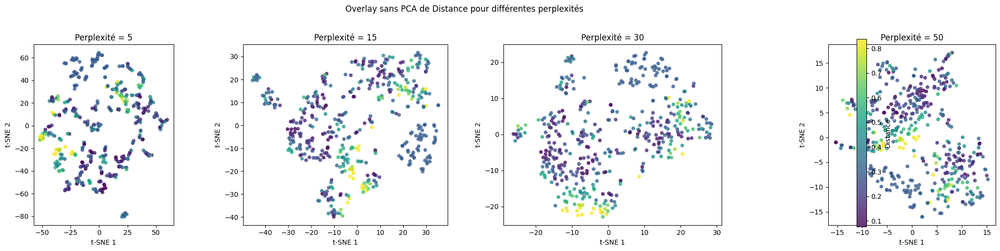

In [14]:
perplexities = [5, 15, 30, 50]
for feature in features_to_overlay:
    if feature not in df.columns:
        print(f"Feature non trouvée : {feature}")
        continue

    vals = df[feature].values
    if vals.dtype == bool:
        vals = vals.astype(int)

    vmin, vmax = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)

    fig, axes = plt.subplots(1, len(perplexities), figsize=(22, 5))
    if len(perplexities) == 1:
        axes = [axes]

    sc = None
    for ax, perp in zip(axes, perplexities):
        tsne = TSNE(
            n_components=2,
            perplexity=perp,
            learning_rate='auto',
            max_iter=1000,
            init='random',
            random_state=42
        )
        X_tsne_perp_random = tsne.fit_transform(X_scaled)
        df_tsne_perp_random = pd.DataFrame(X_tsne_perp_random, columns=['tSNE_1', 'tSNE_2'])
        df_tsne_perp_random['orig_index'] = df.index

        sc = ax.scatter(
            df_tsne_perp_random['tSNE_1'], df_tsne_perp_random['tSNE_2'],
            c=vals, cmap='viridis', vmin=vmin, vmax=vmax,
            alpha=0.8, s=30, edgecolors='none'
        )
        ax.set_title(f'Perplexité = {perp}')
        ax.set_xlabel('t-SNE 1')
        ax.set_ylabel('t-SNE 2')
        ax.set_aspect('equal')
    
    # Ajouter une seule colorbar partagée pour tous les subplots
    cbar = fig.colorbar(sc, ax=axes, label=feature, pad=0.02, fraction=0.046)
    
    plt.suptitle(f'Overlay sans PCA de {feature} pour différentes perplexités', y=1.02)
    plt.tight_layout()
    safe_feature = feature.replace(' ', '_').replace('/', '_')
    plt.savefig(f'Plots/t_SNE_global/sans_pca/overlay/{safe_feature}_perplexities.png', dpi=150, bbox_inches='tight')
    plt.show()

## t-SNE avec PCA ##

### t-SNE Classification avec PCA init = pca ###

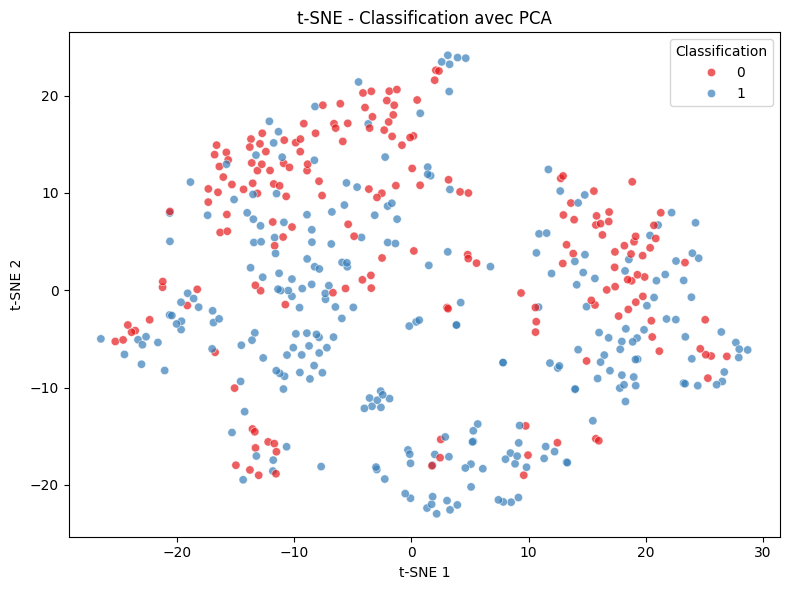

In [15]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    max_iter=1000,
    init='pca',
    random_state=42,
)

# Récupérer la variable classification pour la visualisation t-SNE depuis dataset "Données/Y_train_clean.csv"
y_train = pd.read_csv("Données/Y_train_clean.csv")

X_tsne_pca = tsne.fit_transform(X_scaled)

df_tsne_pca = pd.DataFrame(X_tsne_pca, columns=['tSNE_1', 'tSNE_2'])
df_tsne_pca['orig_index'] = df.index

# Visualisation t-SNE colorée par la classification
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df_tsne_pca['tSNE_1'], y=df_tsne_pca['tSNE_2'], hue=y_train['Classification'], palette='Set1', alpha=0.7)
plt.title('t-SNE - Classification avec PCA')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='Classification')
plt.tight_layout()
plt.savefig('Plots/t_SNE_global/avec_pca/tsne_classification.png', dpi=300)
plt.show()

### Analyse perplexité t-SNE Classification avec PCA ###

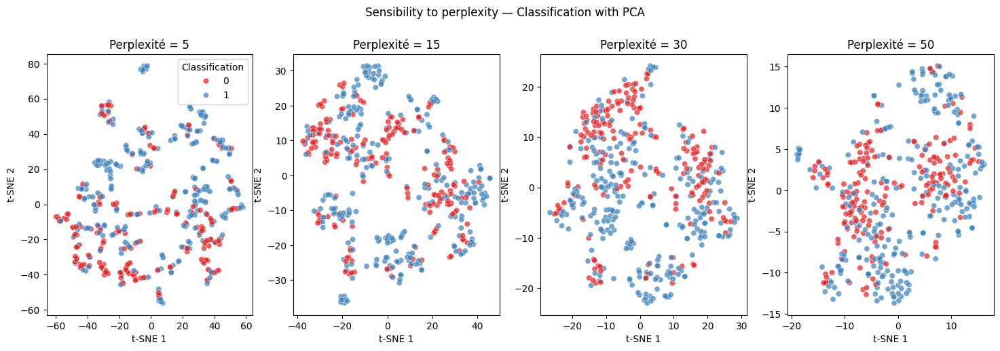

In [16]:
# Analyse de la sensibilité de t-SNE à la perplexité
perplexities = [5, 15, 30, 50]
fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 5))
group_col = 'Classification' if 'Classification' in y_train.columns else print("Colonne 'Classification' non trouvée.")
for i, perp in enumerate(perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        learning_rate='auto',
        max_iter=1000,
        init='pca',
        random_state=42,
    )
    X_tsne_perp_pca = tsne.fit_transform(X_scaled)
    df_tsne_perp_pca = pd.DataFrame(X_tsne_perp_pca, columns=['tSNE_1', 'tSNE_2'])
    df_tsne_perp_pca['orig_index'] = df.index
    
    sns.scatterplot(x=df_tsne_perp_pca['tSNE_1'], y=df_tsne_perp_pca['tSNE_2'], hue=y_train['Classification'], palette='Set1', alpha=0.7, ax=axes[i])
    axes[i].set_title(f'Perplexité = {perp}')
    axes[i].set_xlabel('t-SNE 1')
    axes[i].set_ylabel('t-SNE 2')
    if i == 0:
        axes[i].legend(title='Classification')
    else:
        axes[i].get_legend().remove()
plt.suptitle(f"Sensibility to perplexity — {group_col} with PCA", y=1.02)
# Supprimer les axes vides s'il y en a
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
plt.savefig(f'Plots/t_SNE_global/avec_pca/sensitivity_perplexity.png', dpi=150, bbox_inches='tight')
plt.show()

### Overlay des features numériques avec PCA ###

On superpose une variable continue sur la carte t-SNE pour voir comment elle se structure dans l'espace réduit.

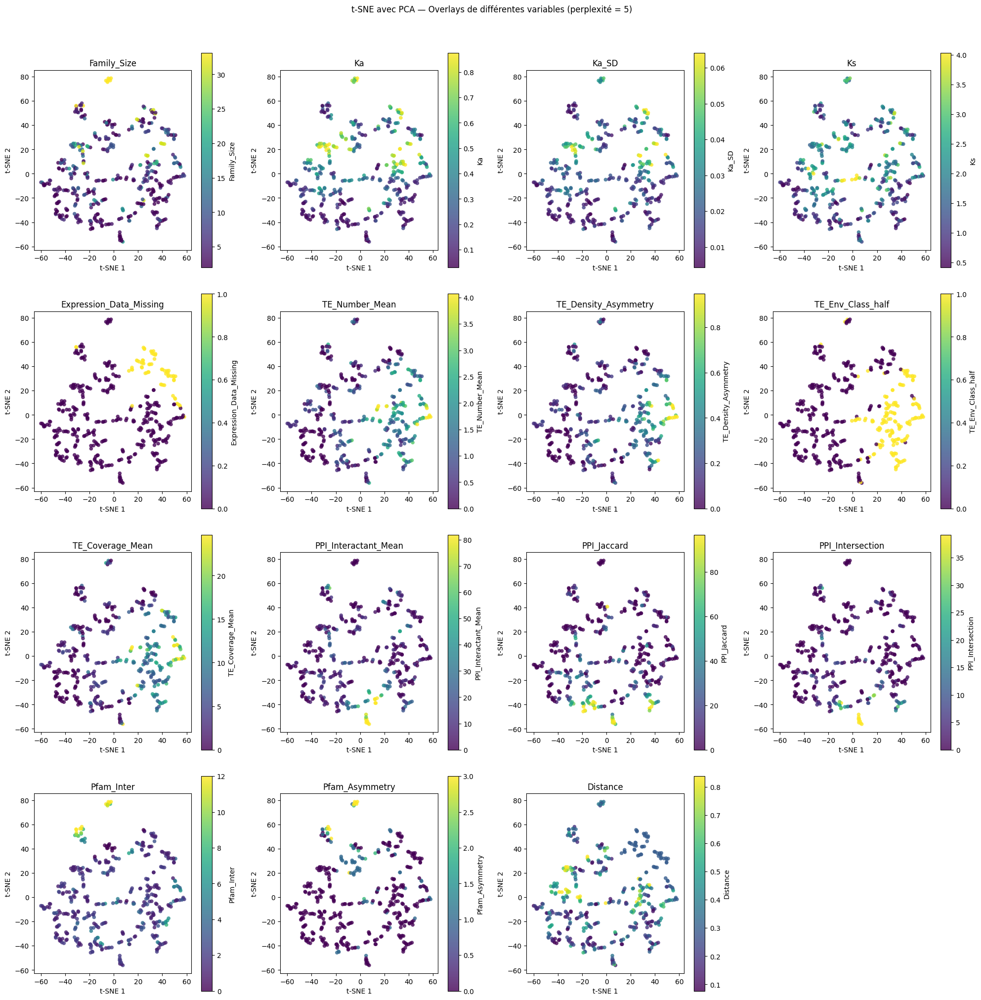

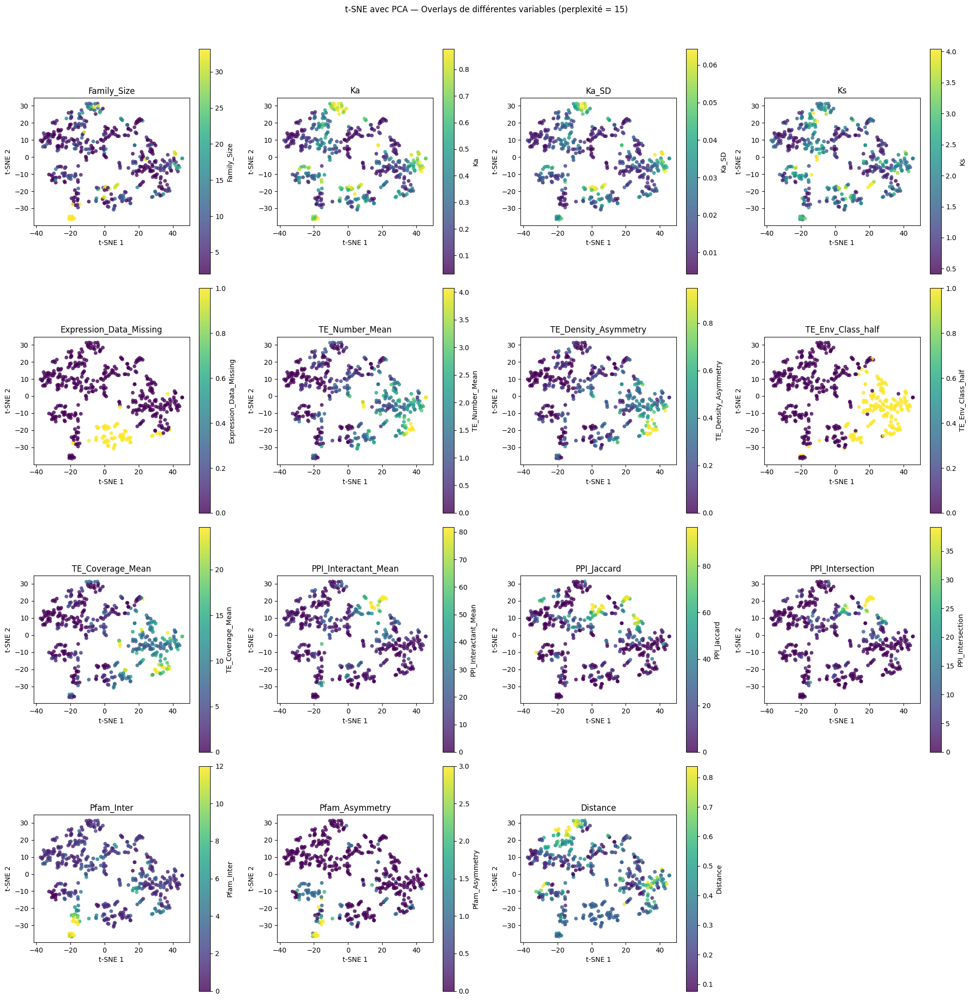

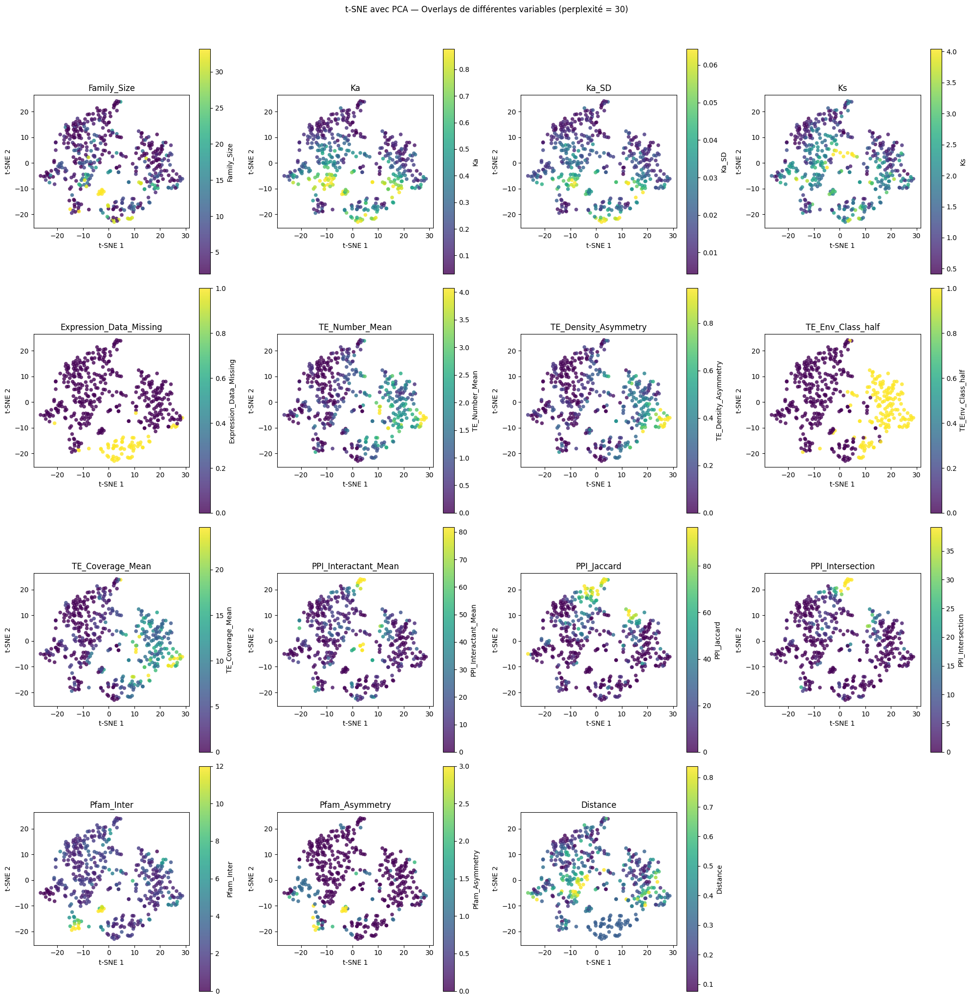

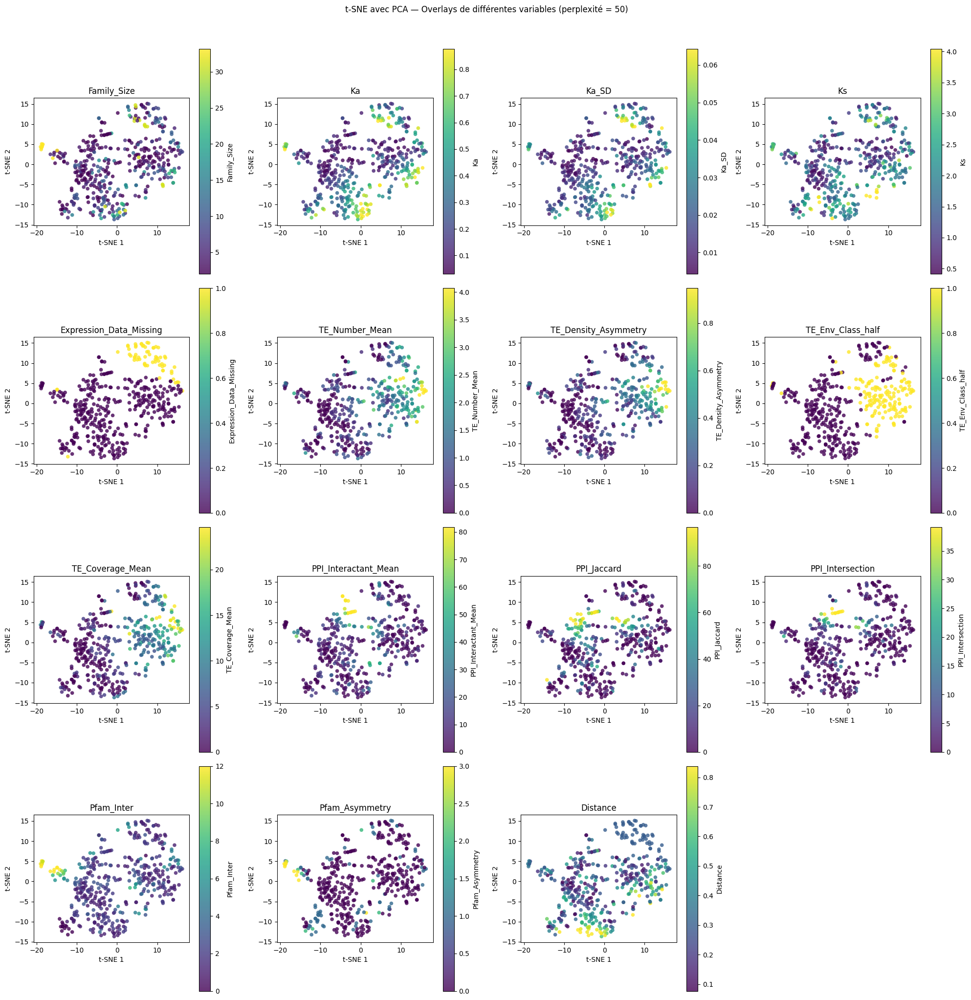

In [17]:
# Fenetre avec 14 overlay pour les variables d'intérêt récupérés via elactic net
features_to_overlay = [
    'Family_Size',
    'Ka', 'Ka_SD', 'Ks',
    'Expression_Data_Missing',
    'TE_Number_Mean', 'TE_Density_Asymmetry', 'TE_Env_Class_half', 'TE_Coverage_Mean',
    'PPI_Interactant_Mean', 'PPI_Jaccard', 'PPI_Intersection',
    'Pfam_Inter', 'Pfam_Asymmetry',
    'Distance'
]
# Figures par descripteurs pour différentes perplexités
perplexities = [5, 15, 30, 50]
for perp in perplexities:
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        learning_rate='auto',
        max_iter=1000,
        init='pca',
        random_state=42
    )
    X_tsne_perp_pca = tsne.fit_transform(X_scaled)
    df_tsne_perp_pca = pd.DataFrame(X_tsne_perp_pca, columns=['tSNE_1', 'tSNE_2'])
    df_tsne_perp_pca['orig_index'] = df.index

    fig, axes = plt.subplots(4, 4, figsize=(20, 20))
    axes = axes.flatten()
    for i, feature in enumerate(features_to_overlay):
        if feature not in df.columns:
            axes[i].set_visible(False)
            continue

        vals = df[feature].values
        if vals.dtype == bool:
            vals = vals.astype(int)

        vmin, vmax = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)
        sc = axes[i].scatter(
            df_tsne_perp_pca['tSNE_1'], df_tsne_perp_pca['tSNE_2'],
            c=vals, cmap='viridis', vmin=vmin, vmax=vmax,
            alpha=0.8, s=30, edgecolors='none'
        )
        axes[i].set_title(feature)
        axes[i].set_xlabel('t-SNE 1')
        axes[i].set_ylabel('t-SNE 2')
        axes[i].set_aspect('equal')
        plt.colorbar(sc, ax=axes[i], label=feature)

    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(f't-SNE avec PCA — Overlays de différentes variables (perplexité = {perp})', y=1.02)
    plt.tight_layout()
    plt.savefig(f'Plots/t_SNE_global/avec_pca/overlay/perplexité_{perp}.png', dpi=150, bbox_inches='tight')
    plt.show()

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


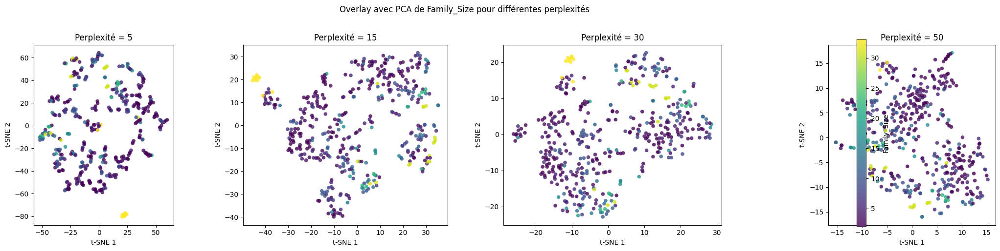

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


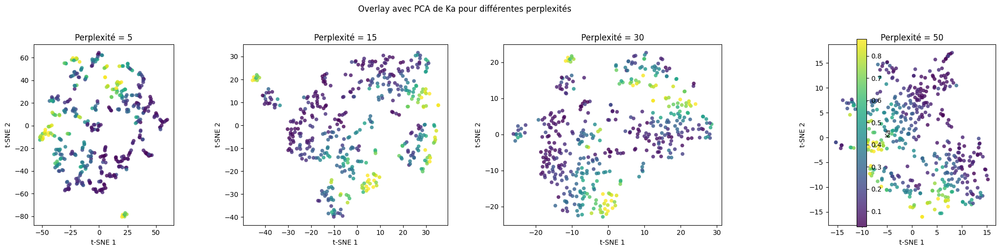

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


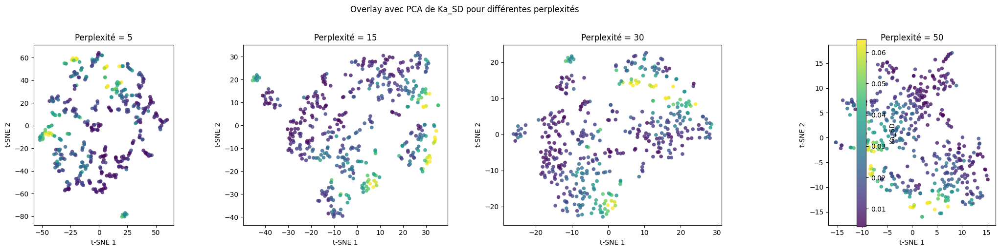

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


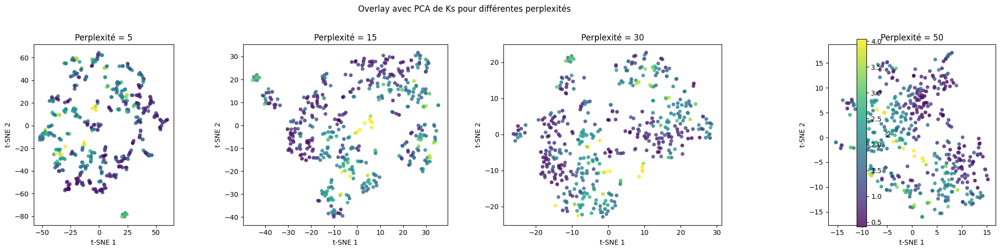

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


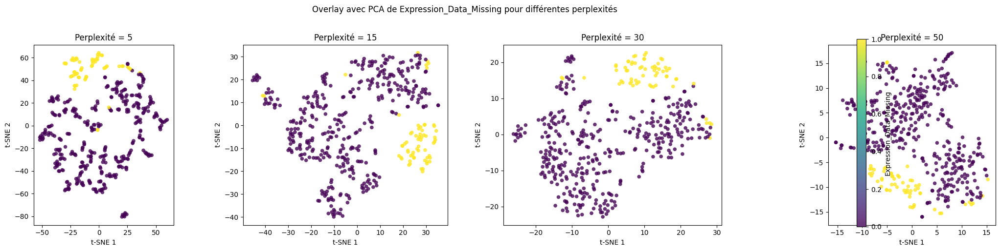

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


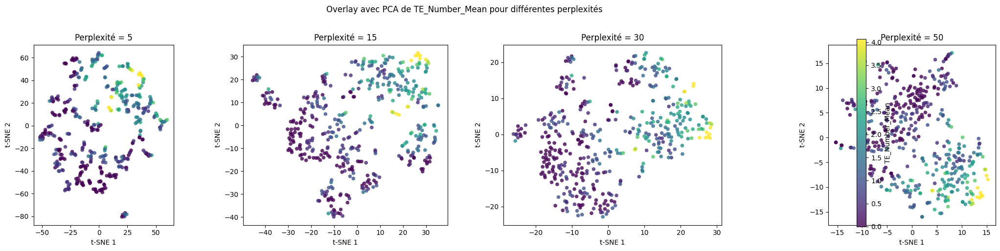

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


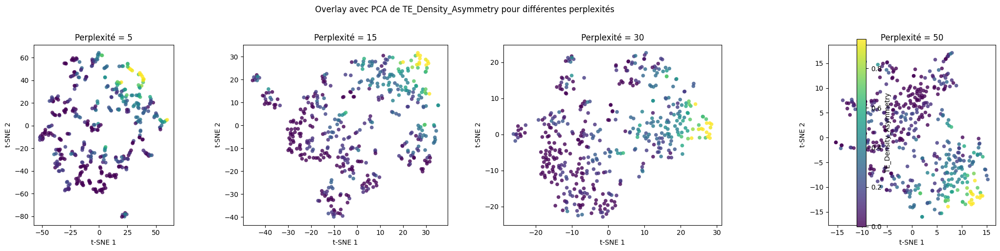

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


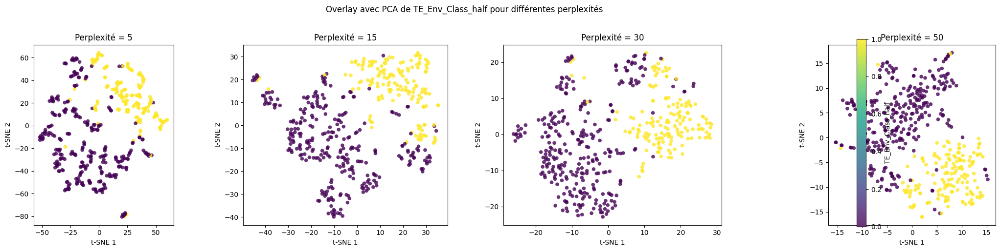

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


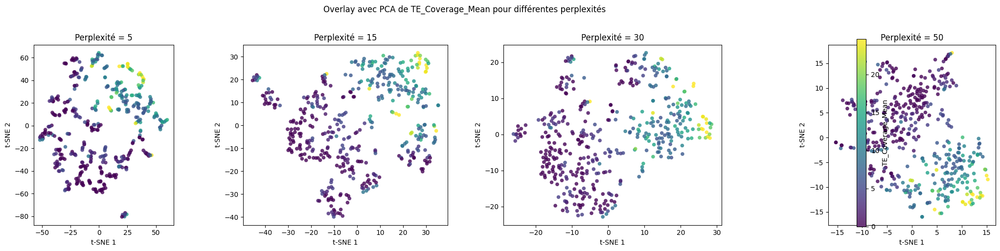

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


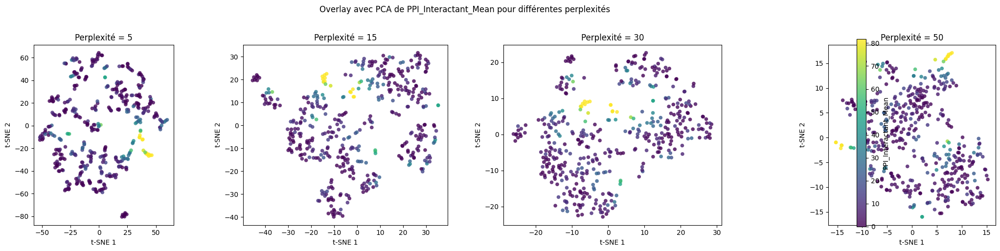

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


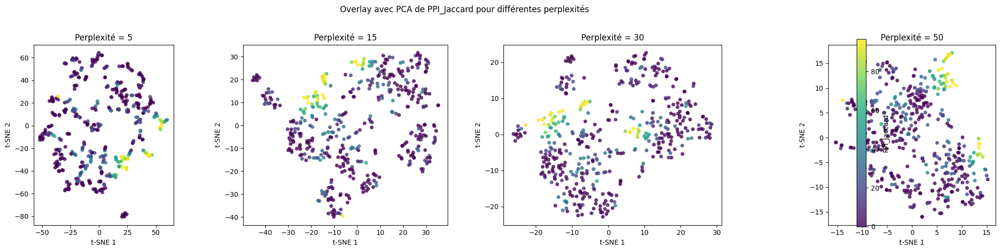

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


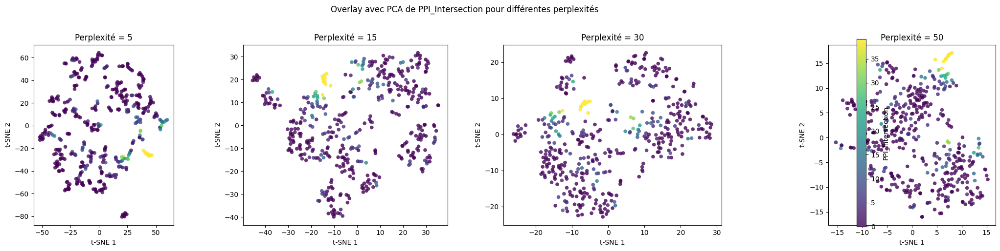

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


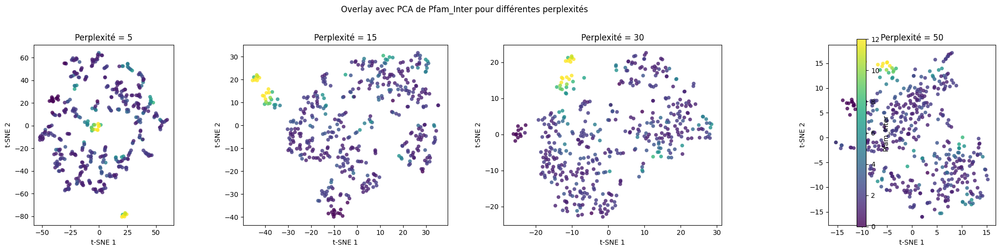

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


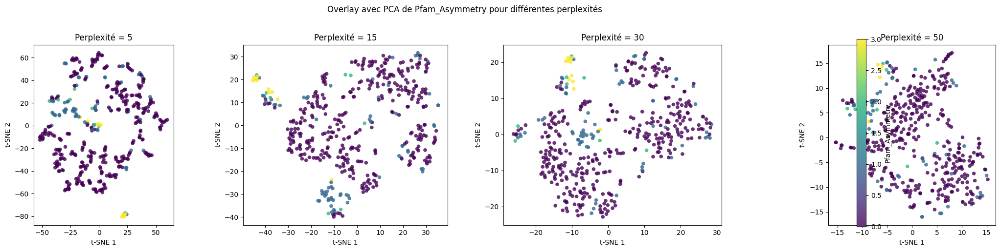

/tmp/ipykernel_9354/2382161400.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


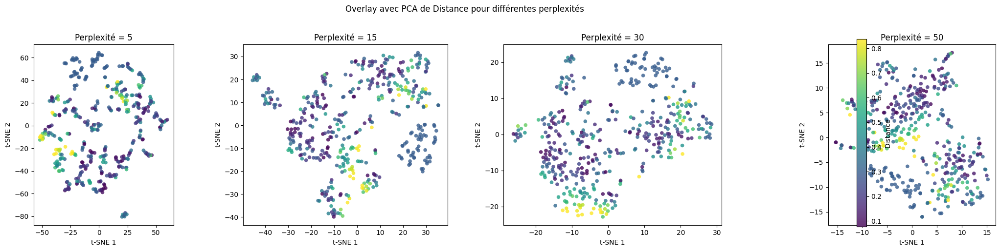

In [18]:
perplexities = [5, 15, 30, 50]
for feature in features_to_overlay:
    if feature not in df.columns:
        print(f"Feature non trouvée : {feature}")
        continue

    vals = df[feature].values
    if vals.dtype == bool:
        vals = vals.astype(int)

    vmin, vmax = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)

    fig, axes = plt.subplots(1, len(perplexities), figsize=(22, 5))
    if len(perplexities) == 1:
        axes = [axes]

    sc = None
    for ax, perp in zip(axes, perplexities):
        tsne = TSNE(
            n_components=2,
            perplexity=perp,
            learning_rate='auto',
            max_iter=1000,
            init='random',
            random_state=42
        )
        X_tsne_perp_pca = tsne.fit_transform(X_scaled)
        df_tsne_perp_pca = pd.DataFrame(X_tsne_perp_pca, columns=['tSNE_1', 'tSNE_2'])
        df_tsne_perp_pca['orig_index'] = df.index

        sc = ax.scatter(
            df_tsne_perp_pca['tSNE_1'], df_tsne_perp_pca['tSNE_2'],
            c=vals, cmap='viridis', vmin=vmin, vmax=vmax,
            alpha=0.8, s=30, edgecolors='none'
        )
        ax.set_title(f'Perplexité = {perp}')
        ax.set_xlabel('t-SNE 1')
        ax.set_ylabel('t-SNE 2')
        ax.set_aspect('equal')
    
    # Ajouter une seule colorbar partagée pour tous les subplots
    cbar = fig.colorbar(sc, ax=axes, label=feature, pad=0.02, fraction=0.046)
    
    plt.suptitle(f'Overlay avec PCA de {feature} pour différentes perplexités', y=1.02)
    plt.tight_layout()
    safe_feature = feature.replace(' ', '_').replace('/', '_')
    plt.savefig(f'Plots/t_SNE_global/avec_pca/overlay/{safe_feature}_perplexities.png', dpi=150, bbox_inches='tight')
    plt.show()